## Setup

In [1]:
from statasetup import *


  ___  ____  ____  ____  ____ ®
 /__    /   ____/   /   ____/      StataNow 19.5
___/   /   /___/   /   /___/       BE—Basic Edition

 Statistics and Data Science       Copyright 1985-2025 StataCorp LLC
                                   StataCorp
                                   4905 Lakeway Drive
                                   College Station, Texas 77845 USA
                                   800-782-8272        https://www.stata.com
                                   979-696-4600        service@stata.com

Stata license: Unlimited-user network, expiring 17 Sep 2027
Serial number: 301909300944
  Licensed to: StataNow/BE 19.5
               TU/e

Notes:
      1. Unicode is supported; see help unicode_advice.


In [2]:
%%stata
use "Datasets\asg1\Roadlighting.dta",clear

## Step 1 - How to perform **simple mediation** analysis when exclusion of one categorical factor level is required?
the manual approach is rather meticulous since `a` `b` `c` and ` c' ` must be studied separately, by using distinct regression lines

**one must be sure** that there are no missing values in place

In [3]:
%%stata
* No missing values so we can proceed to creating the dummy variables
drop if safety ==.
drop if lightsetting ==.
drop if prospect ==. 

* or drop if safety == . | lightsetting == . | prospect == .



. * No missing values so we can proceed to creating the dummy variables
. drop if safety ==.
(0 observations deleted)

. drop if lightsetting ==.
(0 observations deleted)

. drop if prospect ==. 
(0 observations deleted)

. 
. * or drop if safety == . | lightsetting == . | prospect == .
. 


First of all, discard levels of particular categorical variables/mediators if any

In [4]:
%%stata
// as we will only look at spotlight vs the conventional lighting condition, we can get rid of condition 'darkspot' by deleting that data
drop if lightsetting==1
//generate a new dummy variable called spotlight with the conventional lighting as reference (coded 0)
gen spotlight = (lightsetting==2)   //spotlight gets value 1 if lightsetting==2 is true and 0 if false

//let us provide some labels to the new dummy variable 
//first create a label set for spotlight called "labelset"
label define labelset 0 "conventional" 1 "spotlight" 
*check using label list
label list labelset
*then we attach this label set to the spotlight variable
label values spotlight labelset



. // as we will only look at spotlight vs the conventional lighting condition, 
> we can get rid of condition 'darkspot' by deleting that data
. drop if lightsetting==1
(167 observations deleted)

. //generate a new dummy variable called spotlight with the conventional lighti
> ng as reference (coded 0)
. gen spotlight = (lightsetting==2)   //spotlight gets value 1 if lightsetting=
> =2 is true and 0 if false

. 
. //let us provide some labels to the new dummy variable 
. //first create a label set for spotlight called "labelset"
. label define labelset 0 "conventional" 1 "spotlight" 

. *check using label list
. label list labelset
labelset:
           0 conventional
           1 spotlight

. *then we attach this label set to the spotlight variable
. label values spotlight labelset

. 


**`a`** study

In [5]:
%%stata
* a (the first stage of the trajectory): M = I1 +x_light + error_1
reg prospect spotlight


. * a (the first stage of the trajectory): M = I1 +x_light + error_1
. reg prospect spotlight

      Source |       SS           df       MS      Number of obs   =       334
-------------+----------------------------------   F(1, 332)       =      7.12
       Model |  7.87931138         1  7.87931138   Prob > F        =    0.0080
    Residual |  367.651174       332  1.10738305   R-squared       =    0.0210
-------------+----------------------------------   Adj R-squared   =    0.0180
       Total |  375.530485       333  1.12771917   Root MSE        =    1.0523

------------------------------------------------------------------------------
    prospect | Coefficient  Std. err.      t    P>|t|     [95% conf. interval]
-------------+----------------------------------------------------------------
   spotlight |   .3071856   .1151611     2.67   0.008     .0806482     .533723
       _cons |   3.383353   .0814312    41.55   0.000     3.223167    3.543539
----------------------------------

**`b`** and **`c'`**  study - simpler than we expected so don't perceive the mediator's equivalent STATA syntax to be an INTERACTION as for moderated variables. Here we can directly derive from the regression table `b`  and `c'` 

the correct interpretation of c has at its core the part of the effect of i.v. on d.p. that is not account for by changes in the mediator can be seen above

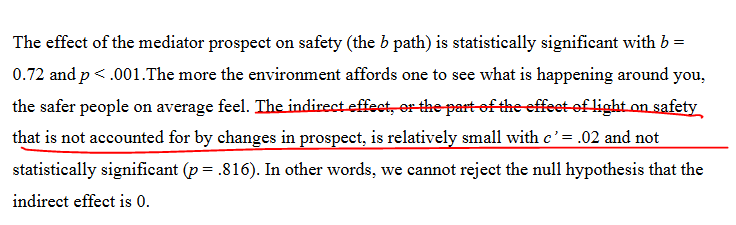

In [6]:
%%stata
* b (the second stage of the trajectory): Y_safety = I1 +bM + x_lightC + error_2
reg safety prospect spotlight  


. * b (the second stage of the trajectory): Y_safety = I1 +bM + x_lightC + erro
> r_2
. reg safety prospect spotlight  

      Source |       SS           df       MS      Number of obs   =       334
-------------+----------------------------------   F(2, 331)       =    194.71
       Model |  195.192058         2  97.5960288   Prob > F        =    0.0000
    Residual |  165.907266       331  .501230411   R-squared       =    0.5405
-------------+----------------------------------   Adj R-squared   =    0.5378
       Total |  361.099324       333  1.08438235   Root MSE        =    .70798

------------------------------------------------------------------------------
      safety | Coefficient  Std. err.      t    P>|t|     [95% conf. interval]
-------------+----------------------------------------------------------------
    prospect |    .719657   .0369233    19.49   0.000      .647023     .792291
   spotlight |    .018273   .0783033     0.23   0.816    -.1357618    .1723079
       _

**`c/the total effect`** study wherefrom the `c'` can be derived by calculating c-ab=c'


In [7]:
%%stata
reg safety spotlight


      Source |       SS           df       MS      Number of obs   =       334
-------------+----------------------------------   F(1, 332)       =      4.46
       Model |  4.78323623         1  4.78323623   Prob > F        =    0.0355
    Residual |  356.316087       332  1.07324123   R-squared       =    0.0132
-------------+----------------------------------   Adj R-squared   =    0.0103
       Total |  361.099324       333  1.08438235   Root MSE        =     1.036



------------------------------------------------------------------------------
      safety | Coefficient  Std. err.      t    P>|t|     [95% conf. interval]
-------------+----------------------------------------------------------------
   spotlight |   .2393413   .1133719     2.11   0.036     .0163235    .4623592
       _cons |   3.323413    .080166    41.46   0.000     3.165716    3.481111
------------------------------------------------------------------------------


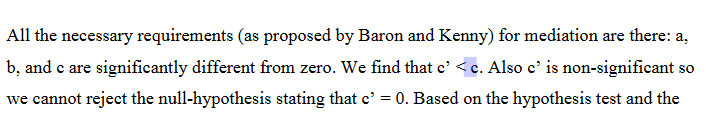

## Step 2 - _ab normality tests_

### Sobel - `sureg(a regression)(b regression)`

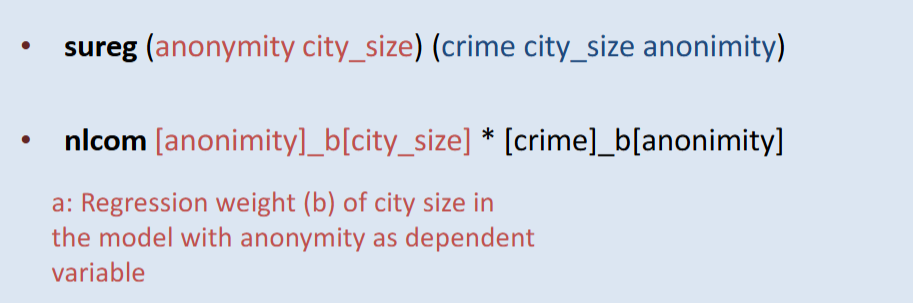

In [8]:
%%stata
sureg (prospect spotlight)(safety spotlight prospect)
nlcom [prospect]_b[spotlight] * [safety]_b[prospect]


. sureg (prospect spotlight)(safety spotlight prospect)



Seemingly unrelated regression
------------------------------------------------------------------------------
Equation             Obs   Params         RMSE  "R-squared"      chi2   P>chi2
------------------------------------------------------------------------------
prospect             334        1     1.049167      0.0210       7.16   0.0075
safety               334        2     .7047896      0.5405     392.96   0.0000
------------------------------------------------------------------------------

------------------------------------------------------------------------------
             | Coefficient  Std. err.      z    P>|z|     [95% conf. interval]
-------------+----------------------------------------------------------------
prospect     |
   spotlight |   .3071856   .1148158     2.68   0.007     .0821509    .5322204
       _cons |   3.383353    .081187    41.67   0.000      3.22423    3.542477
-------------+----------------------------------------------------------------
safe

### Bootstrap - _recycles the aforementioned two steps in a joint loop with `bootrstrap` built-in stata function_

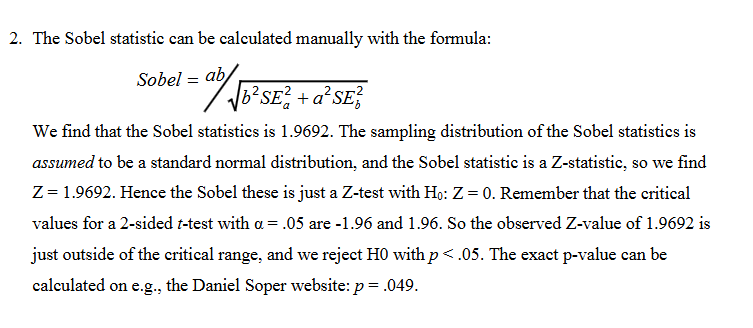

In [9]:
%%stata
capture program drop med

program med, rclass
sureg (prospect spotlight)(safety spotlight prospect)
return scalar ab = [prospect]_b[spotlight] * [safety]_b[prospect]
end

bootstrap r(ab), reps(1000): med 
estat bootstrap, p bc


. capture program drop med

. 
. program med, rclass
  1. sureg (prospect spotlight)(safety spotlight prospect)
  2. return scalar ab = [prospect]_b[spotlight] * [safety]_b[prospect]
  3. end

. 
. bootstrap r(ab), reps(1000): med 
(running med on estimation sample)

Bootstrap replications (1,000): .........10.........20.........30.........40...
> ......50.........60.........70.........80.........90.........100.........110.
> ........120.........130.........140.........150.........160.........170......
> ...180.........190.........200.........210.........220.........230.........24
> 0.........250.........260.........270.........280.........290.........300....
> .....310.........320.........330.........340.........350.........360.........
> 370.........380.........390.........400.........410.........420.........430..
> .......440.........450.........460.........470.........480.........490.......
> ..500.........510.........520.........530.........540.........550.........560
> .........

## Step 3 - Interpretation of a, b, c', ab and c and Baron & Kenny conditions

Interpretation

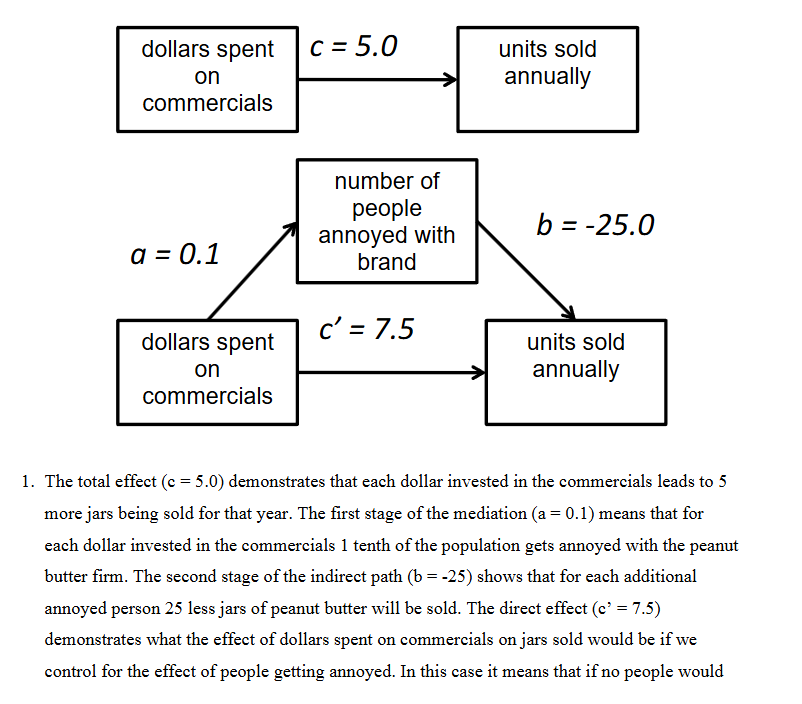

AB Interpretation

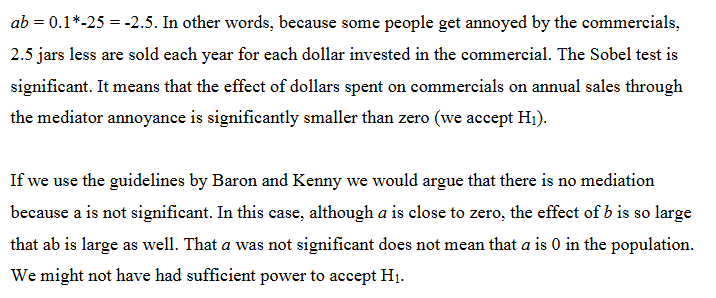


Conditions

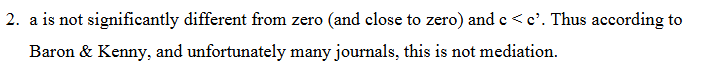

## Step 4 - How to perform **multiple mediation** analysis when exclusion of one categorical factor level is required?

In [ ]:
%%stata
* you can do this again ... gen spotlight = (lightsetting==2)

### Step 4.1 `a1` `a2` and `a3` calculation using the sequential way or `sureg`. I would highly advice for `sureg` to come into effect by the time when all its inputs are thoroughly known. So the manual calculation of `b` and `c'` is also required

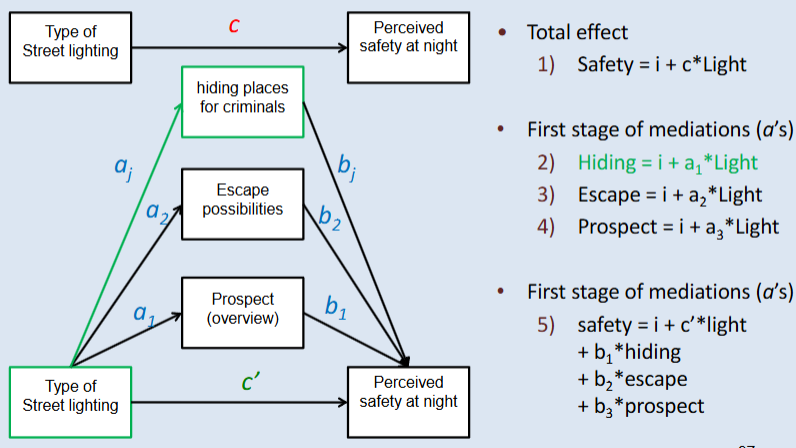

In [21]:
%%stata
* a(s) calculation
*reg prospect spotlight
*reg concealment spotlight
*reg escape spotlight

* c' and b(s) calculations
*reg safety lightsetting prospect concealment escape

* SUREG (multiple factors)
* now use sureg
sureg (prospect spotlight) (concealment spotlight) (escape spotlight) (safety lightsetting prospect concealment escape)


. * a(s) calculation
. *reg prospect spotlight
. *reg concealment spotlight
. *reg escape spotlight
. 
. * c' and b(s) calculations
. *reg safety lightsetting prospect concealment escape
. 
. * SUREG (multiple factors)
. * now use sureg
. sureg (prospect spotlight) (concealment spotlight) (escape spotlight) (safety
>  lightsetting prospect concealment escape)

Seemingly unrelated regression
------------------------------------------------------------------------------
Equation             Obs   Params         RMSE  "R-squared"      chi2   P>chi2
------------------------------------------------------------------------------
prospect             334        1     1.049167      0.0210       7.16   0.0075
concealment          334        1     .9842223      0.0119       4.01   0.0453
escape               334        1     .8783254      0.0319      11.02   0.0009
safety               334        4     .6659938      0.5897     480.12   0.0000
----------------------------------------------------


. 


### 4.2 NLCOM in one go and conducted in a sequential fashion (**Sobel's test**)
Make sure that the a and b are in match with each other, or in other words that the multiplied factors make part of the same route/pathway ` nlcom [first_stage_of_1stpath]_b[a1]*[second_stage_of_2ndpath]_b[b1] + [first_stage_of_2stpat]_b[a2]*[second_stage_of_2stpath]_b[b2] ...` 

In [ ]:
%%stata
* NL COM (multiple factors)
* you can either test each ab combination separately as shown in the picture bellow
nlcom [prospect]_b[spotlight] * [safety]_b[prospect]
nlcom [concealment]_b[spotlight] * [safety]_b[concealment]
nlcom [escape]_b[spotlight] * [safety]_b[escape]

* or all together at once
nlcom [prospect]_b[spotlight]*[safety]_b[prospect] + [concealment]_b[spotlight]*[safety]_b[concealment] + [escape]_b[spotlight]*[safety]_b[escape]


. * NL COM (multiple factors)
. * you can either test each ab combination separately as shown in the picture 
> bellow
. nlcom [prospect]_b[spotlight] * [safety]_b[prospect]

       _nl_1: [prospect]_b[spotlight] * [safety]_b[prospect]



------------------------------------------------------------------------------
             | Coefficient  Std. err.      z    P>|z|     [95% conf. interval]
-------------+----------------------------------------------------------------
       _nl_1 |    .168848   .0647037     2.61   0.009      .042031     .295665
------------------------------------------------------------------------------

. nlcom [concealment]_b[spotlight] * [safety]_b[concealment]

       _nl_1: [concealment]_b[spotlight] * [safety]_b[concealment]

------------------------------------------------------------------------------
             | Coefficient  Std. err.      z    P>|z|     [95% conf. interval]
-------------+----------------------------------------------------------------
       _nl_1 |   .0326075   .0195096     1.67   0.095    -.0056307    .0708456
------------------------------------------------------------------------------

. nlcom [escape]_b[spotlight] * [safety]_b[escape]

       _nl_1: [escape]_b[

### 4.3 or test for sum(ab)!=0 by using bootstraping

In [ ]:
%%stata
capture program drop med

program multimed, rclass
sureg (prospect spotlight) (concealment spotlight) (escape spotlight) (safety lightsetting prospect concealment escape)
return scalar indesc = [escape]_b[spotlight]*[safety]_b[escape]
return scalar indhid = [concealment]_b[spotlight]*[safety]_b[concealment]
return scalar indpro = [prospect]_b[spotlight]*[safety]_b[prospect]
return scalar indtotal = [prospect]_b[spotlight]*[safety]_b[prospect] + [concealment]_b[spotlight]*[safety]_b[concealment] + [escape]_b[spotlight]*[safety]_b[escape]
end

bootstrap r(indesc) r(indhid) r(indpro) r(indtotal), reps(3000): multimed 
estat bootstrap, p bc


. capture program drop med

. 
. program multimed, rclass
  1. sureg (prospect spotlight) (concealment spotlight) (escape spotlight) (saf
> ety lightsetting prospect concealment escape)
  2. return scalar indesc = [escape]_b[spotlight]*[safety]_b[escape]
  3. return scalar indhid = [concealment]_b[spotlight]*[safety]_b[concealment]
  4. return scalar indpro = [prospect]_b[spotlight]*[safety]_b[prospect]
  5. return scalar indtotal = [prospect]_b[spotlight]*[safety]_b[prospect] + [c
> oncealment]_b[spotlight]*[safety]_b[concealment] + [escape]_b[spotlight]*[saf
> ety]_b[escape]
  6. end

. 
. bootstrap r(indesc) r(indhid) r(indpro) r(indtotal), reps(1000): multimed 
(running multimed on estimation sample)



Bootstrap replications (1,000): .........10.........20.........30.........40...
> ......50.........60.........70.........80.........90.........100.........110.
> ........120.........130.........140.........150.........160.........170......
> ...180.........190.........200.........210.........220.........230.........24
> 0.........250.........260.........270.........280.........290.........300....
> .....310.........320.........330.........340.........350.........360.........
> 370.........380.........390.........400.........410.........420.........430..
> .......440.........450.........460.........470.........480.........490.......
> ..500.........510.........520.........530.........540.........550.........560
> .........570.........580.........590.........600.........610.........620.....
> ....630.........640.........650.........660.........670.........680.........6
> 90.........700.........710.........720.........730.........740.........750...
> ......760.........770.........780....